<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/Jobsheet%20Dataset%20PBL/JS11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JOBSHEET 11: KLASIFIKASI II (SUPPORT VECTOR MACHINE — SVM)
### Klasifikasi Tiga Kelas Harga Properti Multi-Kota Indonesia Berbasis SVM (Linear, RBF, Polynomial), Visualisasi Margin & Support Vectors 2D, Serta Hyperparameter Tuning GridSearchCV pada Dataset PBL RumahPoint
**Mata Kuliah:** Pembelajaran Mesin — Semester 5 (Tahun Akademik 2025/2026)  
**Mahasiswa:** Wahyudi Satriawan Hamid  
**NIM / Kelas:** 244107020137 / TI-3H  
**Program Studi:** D-IV Teknik Informatika — Jurusan Teknologi Informasi — Politeknik Negeri Malang  

---


## Bagian 1 — Pemuatan Data, Splitting Anti-Leakage, & Rekayasa Fitur Terkurasi


In [1]:
# ==============================================================================
# BAGIAN 1.1: IMPORT LIBRARY, KONFIGURASI, & LOADER DATA DUAL-MODE
# ==============================================================================
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.svm import LinearSVC, SVC
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc,
    confusion_matrix,
    classification_report
)

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 100

print("=" * 80)
print("SISTEM INFORMASI LINGKUNGAN KOMPUTASI (GOOGLE COLAB / LOCAL JUPYTER)")
print("=" * 80)
print(f"Versi Python        : {sys.version.split()[0]}")
print(f"Versi NumPy         : {np.__version__}")
print(f"Versi Pandas        : {pd.__version__}")
import sklearn
print(f"Versi Scikit-Learn  : {sklearn.__version__}")

# Pemuatan data cerdas dual-mode
DATASET_FILENAME = "properti_multi_kota_clean.csv"
LOCAL_PATH = os.path.join("..", "Dataset", DATASET_FILENAME)
GITHUB_RAW_URL = f"https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/{DATASET_FILENAME}"

if os.path.exists(LOCAL_PATH):
    print(f"[LOADER] Memuat dataset dari penyimpanan lokal: {LOCAL_PATH}")
    df = pd.read_csv(LOCAL_PATH)
else:
    print(f"[LOADER] Path lokal tidak ditemukan. Mengunduh langsung dari GitHub RAW: {GITHUB_RAW_URL}")
    df = pd.read_csv(GITHUB_RAW_URL)

print(f"[LOADER] Berhasil memuat data: {df.shape[0]:,} baris, {df.shape[1]} kolom.")
print("=" * 80)
df.head()

SISTEM INFORMASI LINGKUNGAN KOMPUTASI (GOOGLE COLAB / LOCAL JUPYTER)
Versi Python        : 3.13.18
Versi NumPy         : 2.4.6
Versi Pandas        : 2.2.3
Versi Scikit-Learn  : 1.6.1
[LOADER] Path lokal tidak ditemukan. Mengunduh langsung dari GitHub RAW: https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/properti_multi_kota_clean.csv
[LOADER] Berhasil memuat data: 56,170 baris, 12 kolom.


,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga,kondisi,lokasi_bersih,kelas_harga,kelas_harga_biner
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08,Bekas,Tangerang,Murah,Murah
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09,Bekas,Bekasi,Sedang,Mahal
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09,Bekas,Bekasi,Mahal,Mahal
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09,Bekas,Bekasi,Mahal,Mahal
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08,Bekas,Depok,Sedang,Murah


In [2]:
# ==============================================================================
# BAGIAN 1.2: REKAYASA FITUR DOMAIN, STRATIFIED SPLIT, TOP-15 LOKASI, & PREPROCESSOR
# ==============================================================================
# 1. Rekayasa Fitur Domain Deterministik Terkurasi (100% Konsisten JS09, Tanpa total_ruangan)
df_model = df.copy()

# Fitur 1: Indikator Properti Komersial (0 kamar tidur)
df_model['is_komersil'] = (df_model['jumlah_kamar'] == 0).astype(int)

# Fitur 2: Rasio Luas Bangunan terhadap Luas Tanah (Building-to-Land Ratio)
df_model['rasio_bangunan_tanah'] = df_model['luas_bangunan'] / df_model['luas_m2']

# Fitur 3: Rasio Kamar Mandi per Kamar Tidur (Luxury Ratio)
df_model['rasio_km_kt'] = df_model['jumlah_kamar_mandi'] / (df_model['jumlah_kamar'] + 1)

# Fitur 4: Luas Bangunan per Kamar (Spaciousness Metric)
df_model['luas_per_kamar'] = df_model['luas_bangunan'] / (df_model['jumlah_kamar'] + 1)

print("[FEATURE ENGINEERING] 4 Fitur domain berhasil dibuat.")
print("Catatan: 'total_ruangan' dieksklusi karena multikolinearitas linier sempurna (VIF > 10).")

# 2. Pemisahan Matriks Fitur dan Target (Anti Target-Leakage Wajib)
cols_drop_leakage = ['harga', 'kelas_harga_biner', 'sumber', 'lokasi', 'usia_bangunan', 'kelas_harga']
X_raw = df_model.drop(columns=cols_drop_leakage).copy()
y = df_model['kelas_harga'].copy()

# 3. Stratified Train-Test Split (80% Train / 20% Test) — Identik 100% dengan JS09
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, stratify=y, random_state=42
)

# 4. Reduksi Kardinalitas Top-15 Lokasi Eksklusif dari X_train_raw
top15_lokasi = X_train_raw['lokasi_bersih'].value_counts().nlargest(15).index.tolist()

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()
X_train['lokasi_top15'] = X_train['lokasi_bersih'].apply(lambda x: x if x in top15_lokasi else 'Lainnya')
X_test['lokasi_top15'] = X_test['lokasi_bersih'].apply(lambda x: x if x in top15_lokasi else 'Lainnya')

# 5. Stratified Subsample 8.000 baris eksklusif dari X_train untuk Kernel SVM O(N^2)
X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train, y_train, train_size=8000, stratify=y_train, random_state=42
)

# 6. Definisi Fitur & ColumnTransformer Anti-Leakage (Scaling Wajib pada SVM)
fitur_numerik = [
    'luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi',
    'is_komersil', 'rasio_bangunan_tanah', 'rasio_km_kt', 'luas_per_kamar'
]
fitur_kategorikal = ['lokasi_top15', 'kondisi']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), fitur_numerik),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), fitur_kategorikal)
    ]
)

print("\n" + "=" * 80)
print("DISTRIBUSI DATA & SPESIFIKASI PARTISI ANTI-DATA-LEAKAGE")
print("=" * 80)
print(f"Total Sampel Dataset     : {df_model.shape[0]:,} baris")
print(f"X_train Penuh (LinearSVC): {X_train.shape[0]:,} baris (80.0%)")
print(f"X_train_sub (Kernel SVM) : {X_train_sub.shape[0]:,} baris (~17.8% dari train)")
print(f"X_test Bersama (Uji)     : {X_test.shape[0]:,} baris (20.0%)")
print("=" * 80)

df_dist_summary = pd.DataFrame({
    'Train Penuh (Jml)': y_train.value_counts(),
    'Train Penuh (%)': y_train.value_counts(normalize=True).mul(100),
    'Train Sub (Jml)': y_train_sub.value_counts(),
    'Train Sub (%)': y_train_sub.value_counts(normalize=True).mul(100),
    'Test Penuh (Jml)': y_test.value_counts(),
    'Test Penuh (%)': y_test.value_counts(normalize=True).mul(100)
})
display(df_dist_summary)

[FEATURE ENGINEERING] 4 Fitur domain berhasil dibuat.
Catatan: 'total_ruangan' dieksklusi karena multikolinearitas linier sempurna (VIF > 10).

DISTRIBUSI DATA & SPESIFIKASI PARTISI ANTI-DATA-LEAKAGE
Total Sampel Dataset     : 56,170 baris
X_train Penuh (LinearSVC): 44,936 baris (80.0%)
X_train_sub (Kernel SVM) : 8,000 baris (~17.8% dari train)
X_test Bersama (Uji)     : 11,234 baris (20.0%)


,Train Penuh (Jml),Train Penuh (%),Train Sub (Jml),Train Sub (%),Test Penuh (Jml),Test Penuh (%)
kelas_harga,,,,,,
Mahal,14976,33.327399,2666,33.3250,3744,33.327399
Murah,14978,33.331850,2667,33.3375,3745,33.336301
Sedang,14982,33.340751,2667,33.3375,3745,33.336301



## Bagian 2 — Visualisasi Konsep Margin, Decision Boundary, & Support Vectors (Adaptasi Praktikum 1–3)


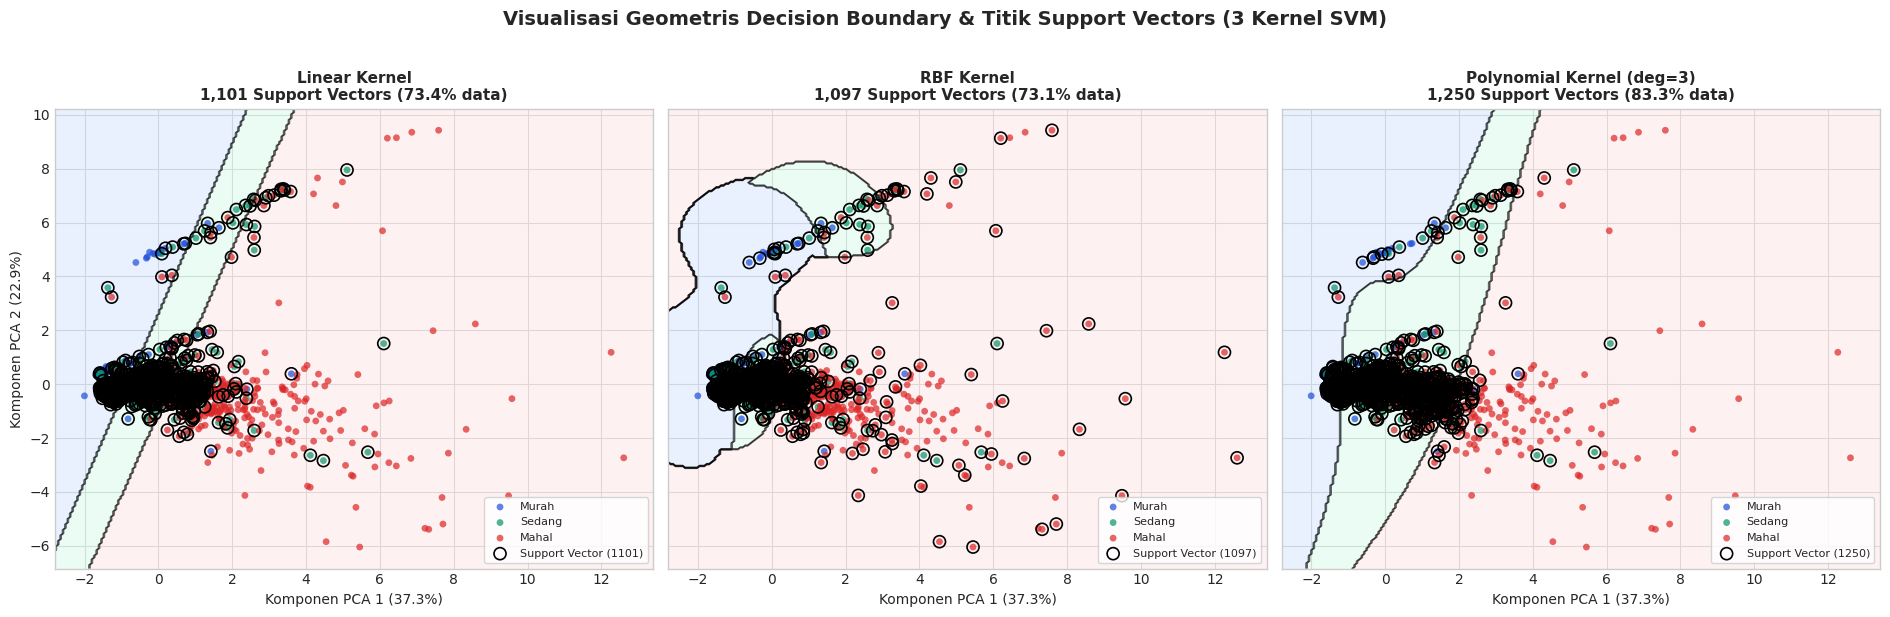

In [3]:
# ==============================================================================
# BAGIAN 2: PROYEKSI PCA 2D & VISUALISASI BOUNDARY + SUPPORT VECTORS 3 KERNEL
# ==============================================================================
from matplotlib.colors import ListedColormap

# 1. Ambil 1.500 sampel terstratifikasi dari X_train_sub untuk visualisasi jernih
X_vis_df, _, y_vis_series, _ = train_test_split(
    X_train_sub, y_train_sub, train_size=1500, stratify=y_train_sub, random_state=42
)

# 2. Transformasi Pra-pemrosesan & Reduksi Dimensi ke 2 Komponen PCA
preprocessor_vis = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), fitur_numerik),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), fitur_kategorikal)
    ]
)

X_vis_proc = preprocessor_vis.fit_transform(X_vis_df)
pca_2d = PCA(n_components=2, random_state=42)
X_vis_2d = pca_2d.fit_transform(X_vis_proc)

# Encoding numerik label target untuk pemetaan warna kontur
kelas_urutan = ['Murah', 'Sedang', 'Mahal']
label_to_idx = {nama: idx for idx, nama in enumerate(kelas_urutan)}
y_vis_idx = y_vis_series.map(label_to_idx).to_numpy()

# 3. Latih 3 Model SVC pada Ruang 2D (Linear, RBF, Polynomial)
kernel_models_2d = {
    'Linear Kernel': SVC(kernel='linear', C=1.0, random_state=42),
    'RBF Kernel': SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42),
    'Polynomial Kernel (deg=3)': SVC(kernel='poly', degree=3, C=1.0, gamma='scale', random_state=42)
}

for name, model in kernel_models_2d.items():
    model.fit(X_vis_2d, y_vis_idx)

# 4. Buat Meshgrid Kontur Decision Boundary
x_min, x_max = X_vis_2d[:, 0].min() - 0.8, X_vis_2d[:, 0].max() + 0.8
y_min, y_max = X_vis_2d[:, 1].min() - 0.8, X_vis_2d[:, 1].max() + 0.8
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# 5. Plot 3 Panel Kontur Berdampingan
fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharex=True, sharey=True)
cmap_bg = ListedColormap(['#d0e1fd', '#d1fae5', '#fee2e2'])
colors_points = ['#1d4ed8', '#059669', '#dc2626']

for ax, (name, model) in zip(axes, kernel_models_2d.items()):
    # Prediksi batas wilayah pada meshgrid
    Z = model.predict(grid_points).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.45, cmap=cmap_bg)
    ax.contour(xx, yy, Z, colors='k', linewidths=0.7, alpha=0.5)

    # Plot titik sampel data per kelas
    for k_idx, k_nama in enumerate(kelas_urutan):
        mask = (y_vis_idx == k_idx)
        ax.scatter(
            X_vis_2d[mask, 0], X_vis_2d[mask, 1],
            c=colors_points[k_idx], label=k_nama,
            s=24, alpha=0.7, edgecolors='none'
        )

    # Tandai Support Vectors
    sv = model.support_vectors_
    n_sv = len(sv)
    pct_sv = (n_sv / len(X_vis_2d)) * 100
    ax.scatter(
        sv[:, 0], sv[:, 1],
        s=75, linewidths=1.2, facecolors='none',
        edgecolors='black', label=f'Support Vector ({n_sv})'
    )

    ax.set_title(f"{name}\n{n_sv:,} Support Vectors ({pct_sv:.1f}% data)", fontsize=11, fontweight='bold')
    ax.set_xlabel(f"Komponen PCA 1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)")
    if ax == axes[0]:
        ax.set_ylabel(f"Komponen PCA 2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)")
    ax.legend(loc='lower right', frameon=True, fontsize=8)

plt.suptitle("Visualisasi Geometris Decision Boundary & Titik Support Vectors (3 Kernel SVM)", fontsize=14, y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

## Bagian 3 — Komparasi Kernel SVM pada Ruang Fitur Penuh (Full Dimensional Space)

[TRAINING] Melatih model: LinearSVC (Full Train)...
[TRAINING] Melatih model: SVC Linear (Subsample)...
[TRAINING] Melatih model: SVC RBF (Subsample)...
[TRAINING] Melatih model: SVC Poly deg=3 (Subsample)...

TABEL KOMPARASI PERFORMA 4 MODEL BASELINE SVM PADA DATA UJI 11.234 BARIS


,Model SVM,Ukuran Data Latih,Akurasi Test,Macro F1,Waktu Latih (s),Waktu Prediksi (s),Support Vectors
0,LinearSVC (Full Train),44.936 (Penuh),0.669396,0.647979,1.247862,0.034054,N/A (Primal Solver)
1,SVC Linear (Subsample),8.000 (Subsample),0.678476,0.674852,3.295807,2.098574,"5,304 (66.3%)"
2,SVC RBF (Subsample),8.000 (Subsample),0.697258,0.692896,2.670197,6.027627,"5,221 (65.3%)"
3,SVC Poly deg=3 (Subsample),8.000 (Subsample),0.684885,0.684896,4.013043,2.493783,"5,748 (71.9%)"


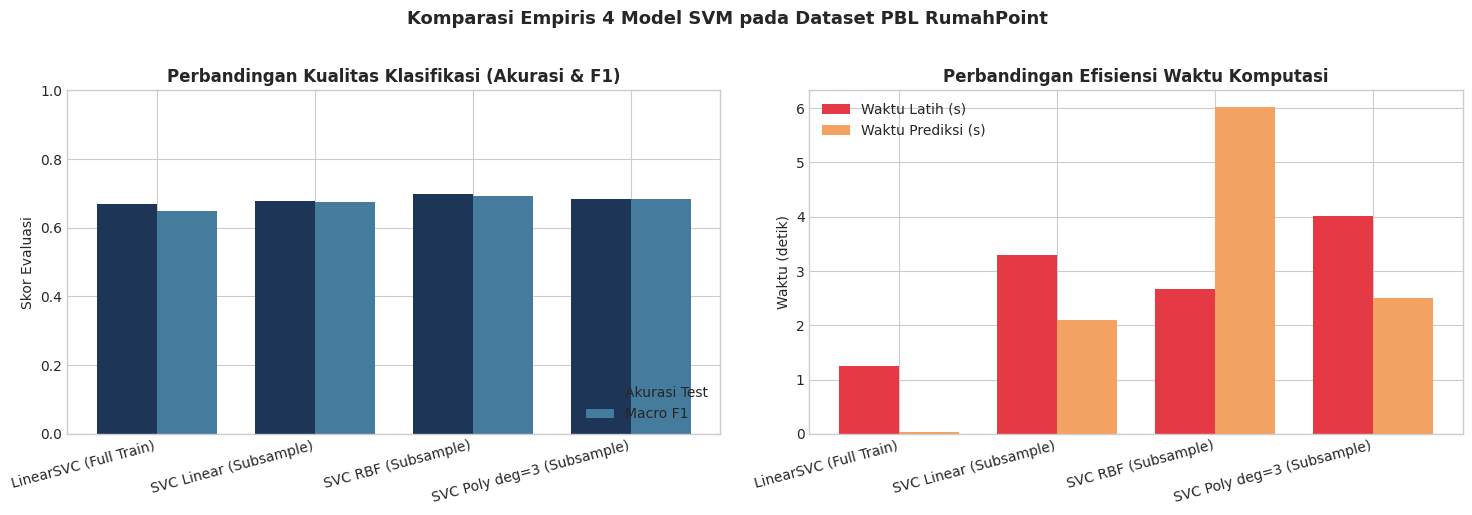

In [4]:
# ==============================================================================
# BAGIAN 3: PELATIHAN & KOMPARASI 4 BASELINE SVM PADA RUANG FITUR PENUH
# ==============================================================================
# 1. Definisi 4 Pipeline SVM pada Ruang Fitur Penuh
svm_baselines = {
    'LinearSVC (Full Train)': (
        Pipeline([
            ('prep', preprocessor),
            ('svm', LinearSVC(C=1.0, max_iter=5000, random_state=42))
        ]),
        X_train, y_train, "44.936 (Penuh)"
    ),
    'SVC Linear (Subsample)': (
        Pipeline([
            ('prep', preprocessor),
            ('svm', SVC(kernel='linear', C=1.0, random_state=42))
        ]),
        X_train_sub, y_train_sub, "8.000 (Subsample)"
    ),
    'SVC RBF (Subsample)': (
        Pipeline([
            ('prep', preprocessor),
            ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
        ]),
        X_train_sub, y_train_sub, "8.000 (Subsample)"
    ),
    'SVC Poly deg=3 (Subsample)': (
        Pipeline([
            ('prep', preprocessor),
            ('svm', SVC(kernel='poly', degree=3, C=1.0, gamma='scale', random_state=42))
        ]),
        X_train_sub, y_train_sub, "8.000 (Subsample)"
    )
}

# 2. Eksekusi Pelatihan, Pencatatan Waktu, dan Evaluasi pada X_test 11.234 Baris
eval_records = []

for nama_model, (pipeline_model, X_tr, y_tr, train_desc) in svm_baselines.items():
    print(f"[TRAINING] Melatih model: {nama_model}...")

    # Ukur waktu pelatihan
    t0_train = time.time()
    pipeline_model.fit(X_tr, y_tr)
    t_train = time.time() - t0_train

    # Ukur waktu prediksi pada X_test penuh (11.234 baris)
    t0_pred = time.time()
    y_pred_test = pipeline_model.predict(X_test)
    t_pred = time.time() - t0_pred

    # Evaluasi metrik performa
    acc = accuracy_score(y_test, y_pred_test)
    f1_mac = f1_score(y_test, y_pred_test, average='macro')

    # Ekstraksi jumlah support vectors
    step_svm = pipeline_model.named_steps['svm']
    if hasattr(step_svm, 'support_vectors_'):
        n_sv_val = f"{len(step_svm.support_vectors_):,} ({len(step_svm.support_vectors_) / len(X_tr) * 100:.1f}%)"
    else:
        n_sv_val = "N/A (Primal Solver)"

    eval_records.append({
        'Model SVM': nama_model,
        'Ukuran Data Latih': train_desc,
        'Akurasi Test': acc,
        'Macro F1': f1_mac,
        'Waktu Latih (s)': t_train,
        'Waktu Prediksi (s)': t_pred,
        'Support Vectors': n_sv_val
    })

df_komparasi = pd.DataFrame(eval_records)
print("\n" + "=" * 80)
print("TABEL KOMPARASI PERFORMA 4 MODEL BASELINE SVM PADA DATA UJI 11.234 BARIS")
print("=" * 80)
display(df_komparasi)

# 3. Visualisasi Bar Chart Perbandingan Akurasi dan Macro F1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
x_pos = np.arange(len(df_komparasi))
bar_width = 0.38

ax1.bar(x_pos - bar_width/2, df_komparasi['Akurasi Test'], width=bar_width, label='Akurasi Test', color='#1d3557')
ax1.bar(x_pos + bar_width/2, df_komparasi['Macro F1'], width=bar_width, label='Macro F1', color='#457b9d')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(df_komparasi['Model SVM'], rotation=15, ha='right')
ax1.set_ylim(0.0, 1.0)
ax1.set_title("Perbandingan Kualitas Klasifikasi (Akurasi & F1)", fontweight='bold')
ax1.set_ylabel("Skor Evaluasi")
ax1.legend(loc='lower right')

ax2.bar(x_pos - bar_width/2, df_komparasi['Waktu Latih (s)'], width=bar_width, label='Waktu Latih (s)', color='#e63946')
ax2.bar(x_pos + bar_width/2, df_komparasi['Waktu Prediksi (s)'], width=bar_width, label='Waktu Prediksi (s)', color='#f4a261')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(df_komparasi['Model SVM'], rotation=15, ha='right')
ax2.set_title("Perbandingan Efisiensi Waktu Komputasi", fontweight='bold')
ax2.set_ylabel("Waktu (detik)")
ax2.legend(loc='upper left')

plt.suptitle("Komparasi Empiris 4 Model SVM pada Dataset PBL RumahPoint", fontsize=13, y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()


## Bagian 4 — Hyperparameter Tuning GridSearchCV pada Kernel RBF & Evaluasi Final (Adaptasi Tugas JS11)

[GRIDSEARCH] Menjalankan GridSearchCV 3-Fold (36 fits) pada 8.000 data latih...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
[GRIDSEARCH] Selesai dalam 77.48 detik.
[GRIDSEARCH] Kombinasi Hyperparameter Terbaik: {'svm__C': 10.0, 'svm__gamma': 0.1}
[GRIDSEARCH] Skor Rata-rata CV Terbaik (Macro F1) : 0.7181


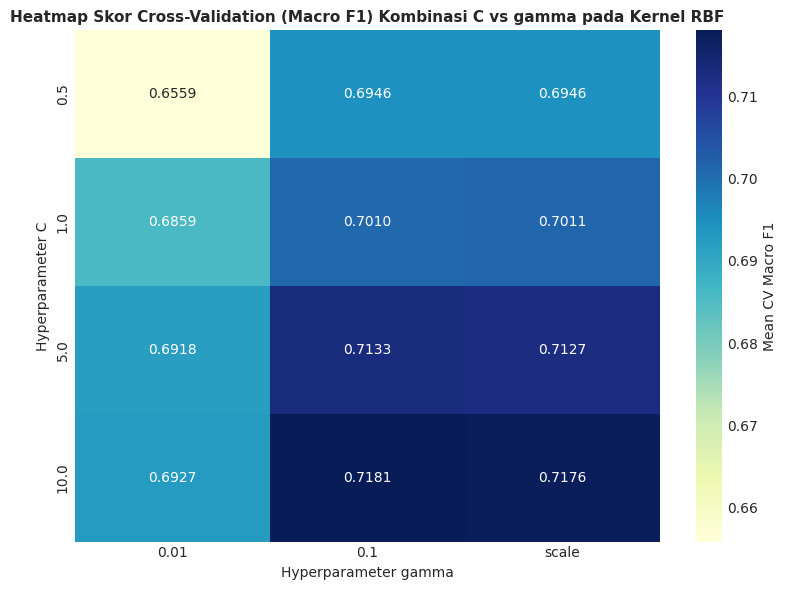

In [5]:
# ==============================================================================
# BAGIAN 4.1: GRIDSEARCHCV HYPERPARAMETER TUNING PADA KERNEL RBF & HEATMAP CV
# ==============================================================================
# 1. Definisi Pipeline Pencarian Hyperparameter
pipe_tune_rbf = Pipeline([
    ('prep', preprocessor),
    ('svm', SVC(kernel='rbf', random_state=42))
])

# 2. Ruang Grid Parameter Terarah untuk Runtime Cepat & Stabil di Colab
param_grid = {
    'svm__C': [0.5, 1.0, 5.0, 10.0],
    'svm__gamma': ['scale', 0.1, 0.01]
}

cv_stratified = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_search_svm = GridSearchCV(
    estimator=pipe_tune_rbf,
    param_grid=param_grid,
    cv=cv_stratified,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

print("=" * 80)
print(f"[GRIDSEARCH] Menjalankan GridSearchCV 3-Fold ({len(param_grid['svm__C']) * len(param_grid['svm__gamma']) * 3} fits) pada 8.000 data latih...")
print("=" * 80)
t0_grid = time.time()
grid_search_svm.fit(X_train_sub, y_train_sub)
t_grid = time.time() - t0_grid

print(f"[GRIDSEARCH] Selesai dalam {t_grid:.2f} detik.")
print(f"[GRIDSEARCH] Kombinasi Hyperparameter Terbaik: {grid_search_svm.best_params_}")
print(f"[GRIDSEARCH] Skor Rata-rata CV Terbaik (Macro F1) : {grid_search_svm.best_score_:.4f}")
print("=" * 80)

# 3. Tabulasi & Heatmap Hasil Cross-Validation
cv_results_df = pd.DataFrame(grid_search_svm.cv_results_)
pivot_cv = cv_results_df.pivot(
    index='param_svm__C',
    columns='param_svm__gamma',
    values='mean_test_score'
)

plt.figure(figsize=(8, 6))
sns.heatmap(pivot_cv, annot=True, fmt='.4f', cmap='YlGnBu', cbar_kws={'label': 'Mean CV Macro F1'})
plt.title("Heatmap Skor Cross-Validation (Macro F1) Kombinasi C vs gamma pada Kernel RBF", fontsize=11, fontweight='bold')
plt.xlabel("Hyperparameter gamma")
plt.ylabel("Hyperparameter C")
plt.tight_layout()
plt.show()

[FINAL MODEL] Melatih ulang model RBF optimal (C=10.0, gamma=0.1) dengan probability=True...
[FINAL MODEL] Pelatihan selesai.

EVALUASI FINAL MODEL TERBAIK SVM KERNEL RBF PADA 11.234 DATA UJI PENUH
Akurasi Pengujian      : 0.7117 (71.17%)
Macro Precision        : 0.7103
Macro Recall           : 0.7117
Macro F1-Score         : 0.7094
Macro ROC-AUC (OvR)    : 0.2877

CLASSIFICATION REPORT LENGKAP:
              precision    recall  f1-score   support

       Murah     0.8107    0.7639    0.7866      3744
      Sedang     0.7206    0.8187    0.7665      3745
       Mahal     0.5995    0.5525    0.5750      3745

    accuracy                         0.7117     11234
   macro avg     0.7103    0.7117    0.7094     11234
weighted avg     0.7102    0.7117    0.7094     11234



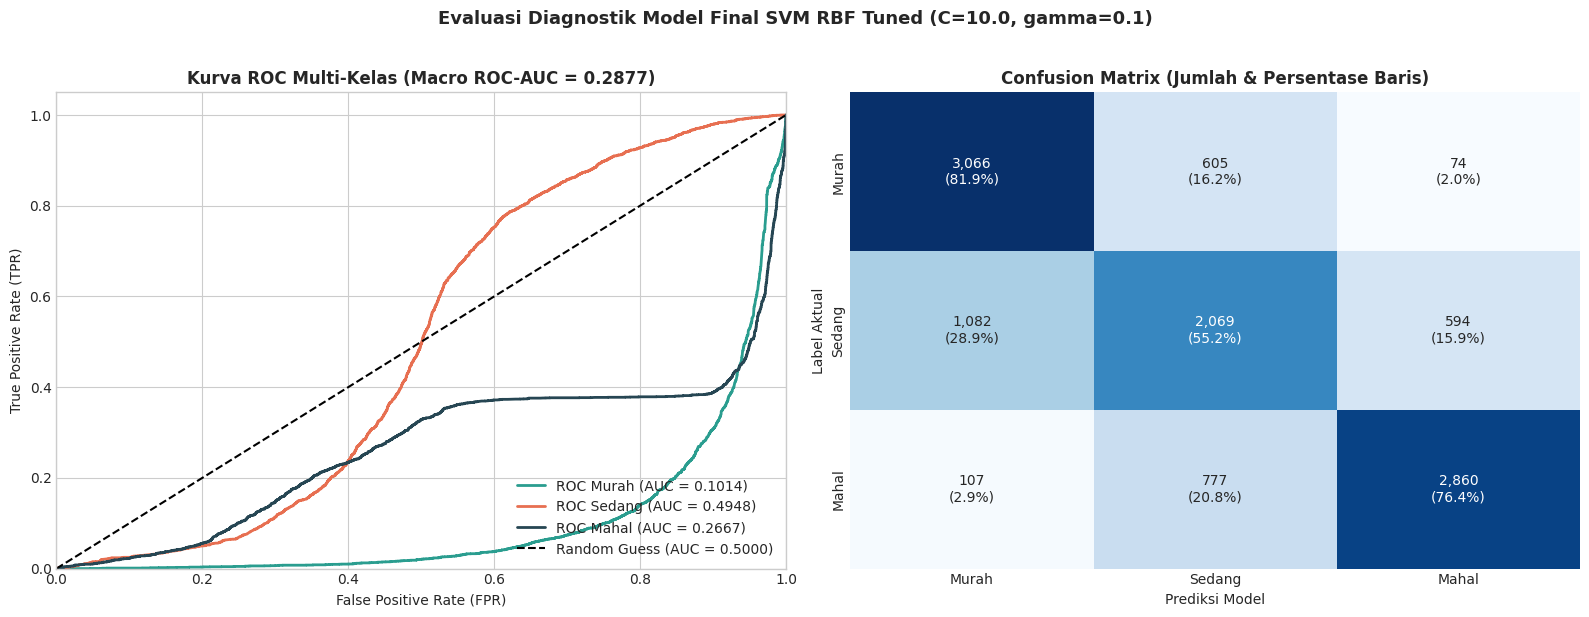

In [6]:
# ==============================================================================
# BAGIAN 4.2: FINAL REFIT (PROBABILITY=TRUE), EVALUASI X_TEST, ROC-AUC, & CONFUSION MATRIX
# ==============================================================================
# 1. Ekstraksi Hyperparameter Terbaik & Refit dengan probability=True
best_c = grid_search_svm.best_params_['svm__C']
best_gamma = grid_search_svm.best_params_['svm__gamma']

print(f"[FINAL MODEL] Melatih ulang model RBF optimal (C={best_c}, gamma={best_gamma}) dengan probability=True...")
final_svm_pipe = Pipeline([
    ('prep', preprocessor),
    ('svm', SVC(kernel='rbf', C=best_c, gamma=best_gamma, probability=True, random_state=42))
])

final_svm_pipe.fit(X_train_sub, y_train_sub)
print("[FINAL MODEL] Pelatihan selesai.")

# 2. Prediksi Kelas & Estimasi Probabilitas pada 11.234 Baris Data Uji Penuh
y_pred_final = final_svm_pipe.predict(X_test)
y_prob_final = final_svm_pipe.predict_proba(X_test)

# 3. Hitung Metrik Evaluasi Komprehensif
acc_final = accuracy_score(y_test, y_pred_final)
prec_final = precision_score(y_test, y_pred_final, average='macro')
rec_final = recall_score(y_test, y_pred_final, average='macro')
f1_final = f1_score(y_test, y_pred_final, average='macro')

# Binarisasi label untuk kurva ROC OvR multi-kelas
target_classes = ['Murah', 'Sedang', 'Mahal']
y_test_bin = label_binarize(y_test, classes=target_classes)
roc_auc_macro = roc_auc_score(y_test_bin, y_prob_final, multi_class='ovr', average='macro')

print("\n" + "=" * 80)
print("EVALUASI FINAL MODEL TERBAIK SVM KERNEL RBF PADA 11.234 DATA UJI PENUH")
print("=" * 80)
print(f"Akurasi Pengujian      : {acc_final:.4f} ({acc_final * 100:.2f}%)")
print(f"Macro Precision        : {prec_final:.4f}")
print(f"Macro Recall           : {rec_final:.4f}")
print(f"Macro F1-Score         : {f1_final:.4f}")
print(f"Macro ROC-AUC (OvR)    : {roc_auc_macro:.4f}")
print("=" * 80)
print("\nCLASSIFICATION REPORT LENGKAP:")
print(classification_report(y_test, y_pred_final, target_names=target_classes, digits=4))

# 4. Visualisasi Kurva ROC Multi-Kelas & Confusion Matrix Heatmap
fig, (ax_roc, ax_cm) = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Kurva ROC per Kelas (One-vs-Rest) & Macro-Average
colors_roc = ['#2a9d8f', '#e76f51', '#264653']
fpr_dict = dict()
tpr_dict = dict()
roc_auc_dict = dict()

for i, nama_kelas in enumerate(target_classes):
    fpr_dict[i], tpr_dict[i], _ = roc_curve(y_test_bin[:, i], y_prob_final[:, i])
    roc_auc_dict[i] = auc(fpr_dict[i], tpr_dict[i])
    ax_roc.plot(fpr_dict[i], tpr_dict[i], color=colors_roc[i], lw=2,
                label=f'ROC {nama_kelas} (AUC = {roc_auc_dict[i]:.4f})')

ax_roc.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess (AUC = 0.5000)')
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel('False Positive Rate (FPR)')
ax_roc.set_ylabel('True Positive Rate (TPR)')
ax_roc.set_title(f'Kurva ROC Multi-Kelas (Macro ROC-AUC = {roc_auc_macro:.4f})', fontweight='bold')
ax_roc.legend(loc="lower right")

# Panel 2: Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred_final, labels=target_classes)
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

annot_labels = np.empty_like(cm, dtype=object)
for r in range(cm.shape[0]):
    for c in range(cm.shape[1]):
        annot_labels[r, c] = f"{cm[r, c]:,}\n({cm_pct[r, c]:.1f}%)"

sns.heatmap(cm, annot=annot_labels, fmt='', cmap='Blues', ax=ax_cm,
            xticklabels=target_classes, yticklabels=target_classes, cbar=False)
ax_cm.set_title('Confusion Matrix (Jumlah & Persentase Baris)', fontweight='bold')
ax_cm.set_xlabel('Prediksi Model')
ax_cm.set_ylabel('Label Aktual')

plt.suptitle(f"Evaluasi Diagnostik Model Final SVM RBF Tuned (C={best_c}, gamma={best_gamma})", fontsize=13, y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()